In [1]:
from pyspark.sql import SparkSession

In [2]:
spark = SparkSession.builder \
    .appName("DPA-Part1") \
    .config("spark.driver.memory", "6g") \
    .config("spark.sql.shuffle.partitions", "50") \
    .getOrCreate()


## 1. Ingestion

Read ListenBrainz to explore the schema

In [3]:
import glob

dump_dirs = sorted(glob.glob("../data/raw/mb/listenbrainz-spark-dump-*/"))
temp = spark.read.parquet(*dump_dirs)
temp.printSchema()


root
 |-- listened_at: timestamp (nullable = true)
 |-- created: timestamp (nullable = true)
 |-- user_id: long (nullable = true)
 |-- recording_msid: string (nullable = true)
 |-- artist_name: string (nullable = true)
 |-- artist_credit_id: long (nullable = true)
 |-- release_name: string (nullable = true)
 |-- release_mbid: string (nullable = true)
 |-- recording_name: string (nullable = true)
 |-- recording_mbid: string (nullable = true)
 |-- artist_credit_mbids: array (nullable = true)
 |    |-- element: string (containsNull = true)



Print the schema of the raw ListenBrainz data

Load ListenBrainz with explicit schema

In [4]:
from pyspark.sql.types import *

lb_schema = StructType([
    StructField("listened_at", TimestampType()),
    StructField("created", TimestampType()),
    StructField("user_id", LongType()),
    StructField("recording_msid", StringType()),
    StructField("artist_name", StringType()),
    StructField("artist_credit_id", LongType()),
    StructField("release_name", StringType()),
    StructField("release_mbid", StringType()),
    StructField("recording_name", StringType()),
    StructField("recording_mbid", StringType()),
    StructField("artist_credit_mbids", ArrayType(StringType())),
])

listens = spark.read.schema(lb_schema).parquet(
    *[d + "*.parquet" for d in dump_dirs]
)

print("Total listens:", listens.count())


Total listens: 39431528


Load artist with explicit schema

In [5]:
artist_schema = StructType([
    StructField("id", IntegerType()),
    StructField("gid", StringType()),
    StructField("name", StringType()),
    StructField("sort_name", StringType()),
    StructField("begin_date_year", IntegerType()),
    StructField("begin_date_month", IntegerType()),
    StructField("begin_date_day", IntegerType()),
    StructField("end_date_year", IntegerType()),
    StructField("end_date_month", IntegerType()),
    StructField("end_date_day", IntegerType()),
    StructField("type", IntegerType()),
    StructField("area", IntegerType()),
    StructField("gender", IntegerType()),
    StructField("comment", StringType()),
    StructField("edits_pending", IntegerType()),
    StructField("last_updated", StringType()),
    StructField("ended", StringType()),
    StructField("begin_area", IntegerType()),
    StructField("end_area", IntegerType()),
])

artist = spark.read.schema(artist_schema) \
    .option("sep", "\t") \
    .option("nullValue", "\\N") \
    .csv("../data/raw/mb/mbdump/artist")

print("Total artists:", artist.count())


Total artists: 3015712


Load area with explicit schema

In [6]:
area_schema = StructType([
    StructField("id", IntegerType()),
    StructField("gid", StringType()),
    StructField("name", StringType()),
    StructField("type", IntegerType()),
    StructField("edits_pending", IntegerType()),
    StructField("last_updated", StringType()),
    StructField("begin_date_year", IntegerType()),
    StructField("begin_date_month", IntegerType()),
    StructField("begin_date_day", IntegerType()),
    StructField("end_date_year", IntegerType()),
    StructField("end_date_month", IntegerType()),
    StructField("end_date_day", IntegerType()),
    StructField("ended", StringType()),
    StructField("comment", StringType()),
])

area = spark.read.schema(area_schema) \
    .option("sep", "\t") \
    .option("nullValue", "\\N") \
    .csv("../data/raw/mb/mbdump/area")

print("Total areas:", area.count())


Total areas: 120108


## 2. Cleaning

 Drop null rows and select only needed columns

In [7]:
from pyspark.sql.functions import col, count, when

listens_clean = listens.dropna(subset=["artist_credit_id"]) \
    .select("listened_at", "user_id", "artist_credit_id", "artist_name", "recording_mbid")

artist_clean = artist.dropna(subset=["area"]) \
    .select("id", "name", "area")

area_clean = area.select("id", "name", "type")

print("listens_clean:", listens_clean.count())
print("artist_clean:", artist_clean.count())
print("area_clean:", area_clean.count())


listens_clean: 31690487
artist_clean: 1497472
area_clean: 120108


Write cleaned tables to parquet

In [8]:
listens_clean.write.mode("overwrite").parquet("../data/processed/listens_clean")
artist_clean.write.mode("overwrite").parquet("../data/processed/artist_clean")
area_clean.write.mode("overwrite").parquet("../data/processed/area_clean")

print("Cleaned tables written.")


Cleaned tables written.


## 3. Spark SQL Analysis

Register cleaned tables as SQL views

In [9]:
listens_clean = spark.read.parquet("../data/processed/listens_clean")
artist_clean = spark.read.parquet("../data/processed/artist_clean")
area_clean = spark.read.parquet("../data/processed/area_clean")

listens_clean.createOrReplaceTempView("listens")
artist_clean.createOrReplaceTempView("artist")
area_clean.createOrReplaceTempView("area")


Main join :link listens to artist origin country (area.type = 1 filters to countries only)


In [10]:
joined = spark.sql("""
    SELECT l.user_id, l.artist_credit_id, a.name AS artist_name, ar.name AS country
    FROM listens l
    JOIN artist a ON l.artist_credit_id = a.id
    JOIN area ar ON a.area = ar.id
    WHERE ar.type = 1
""")

joined.createOrReplaceTempView("joined")
print("Joined rows:", joined.count())
joined.show(5)


Joined rows: 17271689
+-------+----------------+-----------+-------------+
|user_id|artist_credit_id|artist_name|      country|
+-------+----------------+-----------+-------------+
| 200344|              17|  Bob Dylan|United States|
| 200344|              17|  Bob Dylan|United States|
| 200344|              17|  Bob Dylan|United States|
| 200344|              17|  Bob Dylan|United States|
| 200344|              17|  Bob Dylan|United States|
+-------+----------------+-----------+-------------+
only showing top 5 rows



Cache joined table to parquet to avoid recomputing the full join

In [11]:
joined.write.mode("overwrite").parquet("../data/processed/joined")
joined = spark.read.parquet("../data/processed/joined")
joined.createOrReplaceTempView("joined")
print("done")

done


## 4. Analysis

Top 20 artists by total listen count

In [11]:
spark.sql("""
    SELECT artist_name, country, COUNT(*) AS total_listens
    FROM joined
    GROUP BY artist_name, country
    ORDER BY total_listens DESC
    LIMIT 20
""").show(20, truncate=False)


+-------------------+--------------+-------------+
|artist_name        |country       |total_listens|
+-------------------+--------------+-------------+
|Radiohead          |United Kingdom|116926       |
|Die drei ???       |Germany       |115606       |
|Linkin Park        |United States |106635       |
|The Beatles        |United Kingdom|103042       |
|Taylor Swift       |United States |87563        |
|Kexxx              |Japan         |72395        |
|Ye                 |United States |69176        |
|C418               |Germany       |68392        |
|Rammstein          |Germany       |59014        |
|My Chemical Romance|United States |54167        |
|Deftones           |United States |53854        |
|Kendrick Lamar     |United States |53535        |
|Tame Impala        |Australia     |51308        |
|Queen              |United Kingdom|50847        |
|System of a Down   |United States |50162        |
|Coldplay           |United Kingdom|49457        |
|Eminem             |United Sta

Top 10 countries by total listens


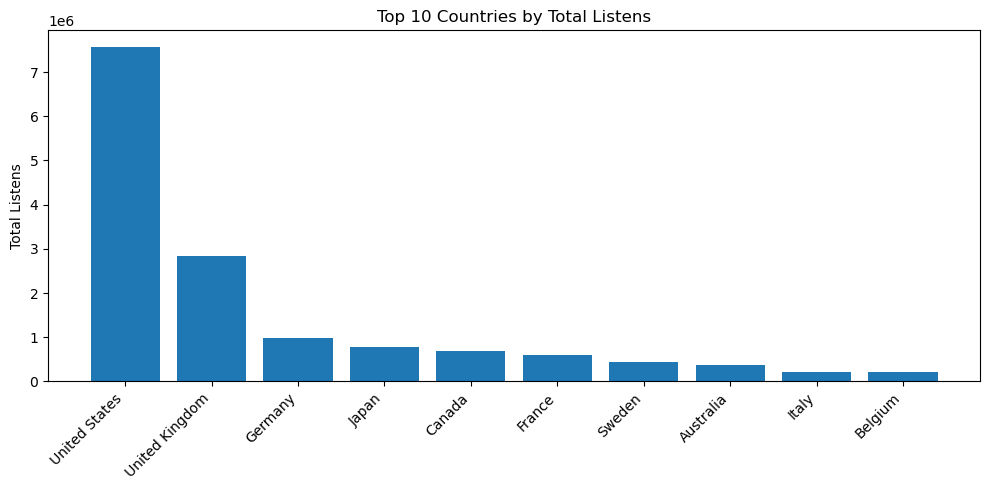

In [12]:
import matplotlib.pyplot as plt

top_countries_pd = spark.sql("""
    SELECT country, COUNT(*) AS total_listens
    FROM joined
    GROUP BY country
    ORDER BY total_listens DESC
    LIMIT 10
""").toPandas()

plt.figure(figsize=(10, 5))
plt.bar(top_countries_pd["country"], top_countries_pd["total_listens"])
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Countries by Total Listens")
plt.ylabel("Total Listens")
plt.tight_layout()
plt.show()

Listens per day (Oct 2026)

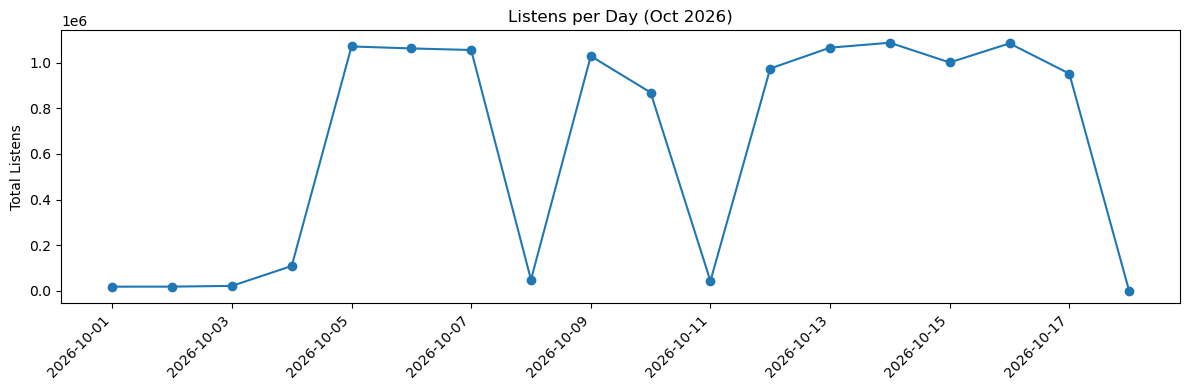

In [13]:
listens_per_day_pd = spark.sql("""
    SELECT DATE(listened_at) AS day, COUNT(*) AS total_listens
    FROM listens
    WHERE listened_at >= '2026-10-01'
    GROUP BY day
    ORDER BY day
""").toPandas()

plt.figure(figsize=(12, 4))
plt.plot(listens_per_day_pd["day"], listens_per_day_pd["total_listens"], marker="o")
plt.xticks(rotation=45, ha="right")
plt.title("Listens per Day (Oct 2026)")
plt.ylabel("Total Listens")
plt.tight_layout()
plt.show()

User activity distribution : most users listen very little, a few listen a lot (heavy skew)


In [14]:
spark.sql("""
    SELECT 
        COUNT(*) AS total_users,
        ROUND(AVG(listen_count), 2) AS avg_listens,
        MAX(listen_count) AS max_listens,
        MIN(listen_count) AS min_listens,
        PERCENTILE(listen_count, 0.5) AS median_listens,
        PERCENTILE(listen_count, 0.9) AS p90_listens
    FROM (
        SELECT user_id, COUNT(*) AS listen_count
        FROM listens
        GROUP BY user_id
    )
""").show(truncate=False)


+-----------+-----------+-----------+-----------+--------------+-----------+
|total_users|avg_listens|max_listens|min_listens|median_listens|p90_listens|
+-----------+-----------+-----------+-----------+--------------+-----------+
|37988      |834.22     |428100     |1          |122.0         |656.0      |
+-----------+-----------+-----------+-----------+--------------+-----------+



User listening diversity:how many distinct artist origin countries does each user listen to?

In [15]:
user_country_diversity = spark.sql("""
    SELECT 
        user_id,
        COUNT(DISTINCT country) AS distinct_countries_listened,
        COUNT(DISTINCT artist_credit_id) AS distinct_artists_listened
    FROM joined
    GROUP BY user_id
    ORDER BY distinct_countries_listened DESC
""")

user_country_diversity.createOrReplaceTempView("user_diversity")
user_country_diversity.show(20, truncate=False)


+-------+---------------------------+-------------------------+
|user_id|distinct_countries_listened|distinct_artists_listened|
+-------+---------------------------+-------------------------+
|201952 |132                        |7145                     |
|214795 |127                        |7833                     |
|206491 |126                        |4865                     |
|179122 |119                        |6133                     |
|209981 |118                        |5205                     |
|216199 |117                        |6357                     |
|208717 |117                        |5018                     |
|205909 |116                        |3687                     |
|210446 |115                        |2657                     |
|183798 |115                        |4797                     |
|210231 |112                        |5652                     |
|206680 |111                        |5548                     |
|204561 |109                        |360

Summary statistics of user listening diversity: total users, average, max, and min distinct artist origin countries per user

In [16]:
spark.sql("""
    SELECT 
        COUNT(DISTINCT user_id) AS total_users,
        ROUND(AVG(distinct_countries_listened), 2) AS avg_countries_per_user,
        MAX(distinct_countries_listened) AS max_countries,
        MIN(distinct_countries_listened) AS min_countries
    FROM user_diversity
""").show()


+-----------+----------------------+-------------+-------------+
|total_users|avg_countries_per_user|max_countries|min_countries|
+-----------+----------------------+-------------+-------------+
|      36481|                  9.72|          132|            1|
+-----------+----------------------+-------------+-------------+



Correlation between artist diversity and geographic diversity

In [17]:
from pyspark.sql.functions import corr

user_country_diversity.select(
    corr("distinct_artists_listened", "distinct_countries_listened").alias("correlation")
).show()


+------------------+
|       correlation|
+------------------+
|0.7210037233116493|
+------------------+



Bridge artist analysis: artists listened to from the most distinct countries
> Note: This query returns no results because every `artist_credit_id` maps to exactly one origin country in MusicBrainz. Bridge behavior cannot be measured by origin country alone and will be addressed in Part 3 using the collaboration graph (`l_artist_artist`).

In [18]:
bridge = spark.sql("""
    SELECT artist_credit_id, artist_name, COUNT(DISTINCT country) AS country_reach
    FROM joined
    GROUP BY artist_credit_id, artist_name
    HAVING country_reach > 1
    ORDER BY country_reach DESC
    LIMIT 20
""")

print("Bridge artists found:", bridge.count())
bridge.show(20, truncate=False)


Bridge artists found: 0
+----------------+-----------+-------------+
|artist_credit_id|artist_name|country_reach|
+----------------+-----------+-------------+
+----------------+-----------+-------------+



Load artist-to-artist relationships

In [19]:
from pyspark.sql.types import *

l_artist_schema = StructType([
    StructField("id", IntegerType()),
    StructField("link", IntegerType()),
    StructField("entity0", IntegerType()),
    StructField("entity1", IntegerType()),
    StructField("entity0_credit", StringType()),
    StructField("entity1_credit", StringType()),
    StructField("edits_pending", IntegerType()),
    StructField("last_updated", StringType()),
    StructField("link_order", IntegerType()),
    StructField("entity0_cardinality", IntegerType()),
    StructField("entity1_cardinality", IntegerType()),
])

l_artist_artist = spark.read.schema(l_artist_schema) \
    .option("sep", "\t") \
    .option("nullValue", "\\N") \
    .csv("../data/raw/mb/mbdump/l_artist_artist")

print("Total relations:", l_artist_artist.count())
l_artist_artist.createOrReplaceTempView("l_artist_artist")


Total relations: 865360
